# Lab 13-11 · Radiation and Antenna Fundamentals

Companion to [chapter 13-11](../../chapters/13-11-radiation-and-antennas.md). Four parts: the Hertzian dipole's near and far fields; dipole patterns by summing elements; link budgets across frequency; and phased arrays with steering and grating lobes. Run the cells in order.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import brentq
c0, eta0 = 299792458.0, 376.7303

## Part 1 · Near and far fields

The broadside $E_\theta$ of a Hertzian dipole has three terms in the ratio $1 : 1/(kr) : 1/(kr)^2$. Plot each against $kr$.

**Predict first:** where do they cross, and which term dominates at $kr$ = 10?

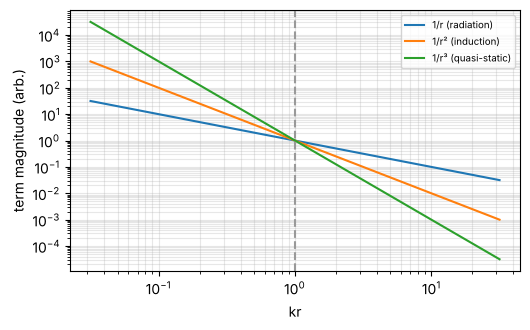

terms equal at kr = 1, r = 0.1592 wavelengths; at kr = 10 the quasi-static term is 1% of the radiation term


In [2]:
kr = np.logspace(-1.5, 1.5, 400)
fig, ax = plt.subplots(figsize=(5.4, 3.4))
for p, label in ((0, '1/r (radiation)'), (1, '1/r² (induction)'), (2, '1/r³ (quasi-static)')):
    ax.loglog(kr, 1 / kr ** (1 + p), label=label)
ax.axvline(1, color='0.6', ls='--'); ax.set_xlabel('kr'); ax.set_ylabel('term magnitude (arb.)'); ax.legend(fontsize=7); ax.grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()
print(f"terms equal at kr = 1, r = {1 / (2 * math.pi):.4f} wavelengths; at kr = 10 the quasi-static term is {1 / 100:.0%} of the radiation term")

## Part 2 · Dipole patterns by summing elements

Approximate the current on a centre-fed dipole of length $L$ as $\sin[k(L/2 - \lvert z\rvert)]$, add the far fields of its elements, and integrate the pattern for directivity.

**Predict first:** is a full-wave dipole more directive than a half-wave one? What happens at 1.5λ?

L = 0.5 lambda: directivity 1.641 (2.15 dBi)
L = 1.0 lambda: directivity 2.411 (3.82 dBi)
L = 1.5 lambda: directivity 2.226 (3.48 dBi)


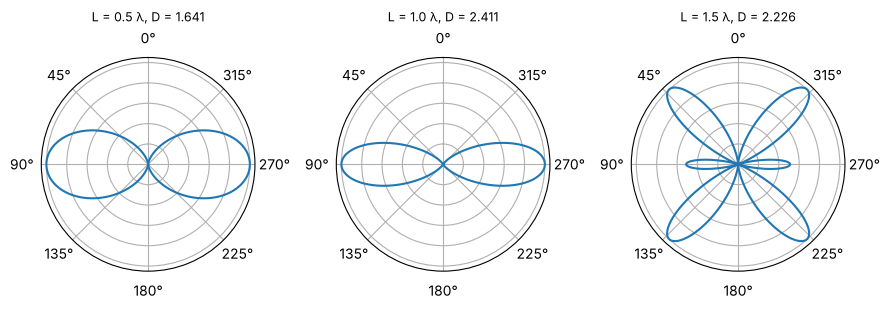

In [3]:
def pattern(L, t):
    k = 2 * math.pi
    return (math.sin(t) * quad(lambda z: math.sin(k * (L / 2 - abs(z))) * math.cos(k * z * math.cos(t)), -L / 2, L / 2, limit=200)[0]) ** 2
th = np.linspace(1e-4, math.pi - 1e-4, 361)
fig = plt.figure(figsize=(9, 3.2))
for i, L in enumerate((0.5, 1.0, 1.5)):
    U = np.array([pattern(L, t) for t in th])
    P = 2 * math.pi * np.trapezoid(U * np.sin(th), th) if hasattr(np, 'trapezoid') else 2 * math.pi * np.trapz(U * np.sin(th), th)
    D = 4 * math.pi * U.max() / P
    ax = fig.add_subplot(1, 3, i + 1, projection='polar'); ax.plot(th, U / U.max()); ax.plot(-th, U / U.max(), color='C0')
    ax.set_theta_zero_location('N'); ax.set_title(f"L = {L} λ, D = {D:.3f}", fontsize=9); ax.set_yticklabels([])
    print(f"L = {L} lambda: directivity {D:.3f} ({10 * math.log10(D):.2f} dBi)")
plt.tight_layout(); plt.show()

## Part 3 · Link budgets across frequency

Received power over 100 m with 20 dBm transmitted, for (a) half-wave dipoles (fixed gain) and (b) antennas of fixed 10 cm² effective aperture.

**Predict first:** which curve rises with frequency?

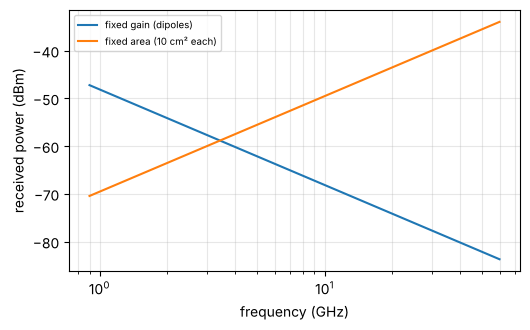

In [4]:
f = np.logspace(math.log10(0.9e9), math.log10(60e9), 200)
lam = c0 / f
Pr_gain = 20 + 2 * 2.15 + 20 * np.log10(lam / (4 * math.pi * 100))
G_area = 4 * math.pi * 1e-3 / lam**2
Pr_area = 20 + 20 * np.log10(G_area) + 20 * np.log10(lam / (4 * math.pi * 100))
fig, ax = plt.subplots(figsize=(5.4, 3.4))
ax.semilogx(f / 1e9, Pr_gain, label='fixed gain (dipoles)'); ax.semilogx(f / 1e9, Pr_area, label='fixed area (10 cm² each)')
ax.set_xlabel('frequency (GHz)'); ax.set_ylabel('received power (dBm)'); ax.legend(fontsize=7); ax.grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()

## Part 4 · Phased arrays

Plot $\lvert\text{AF}\rvert^2$ for 4, 8 and 16 isotropic elements at λ/2, steer 8 elements to 30°, and space 16 elements at 0.8λ steered to 40°.

**Predict first:** where does the grating lobe appear in the last case?

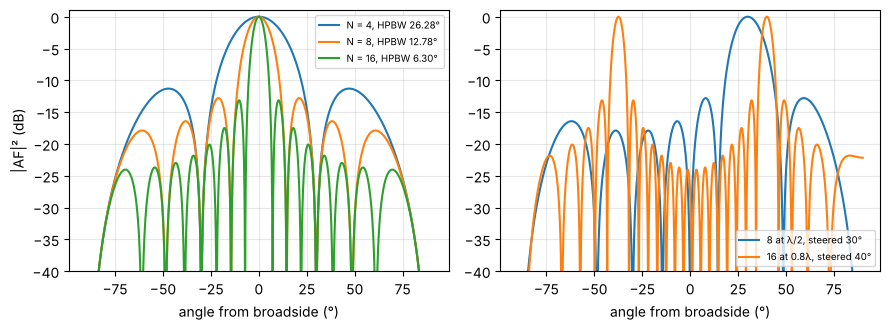

grating lobe for 0.8 lambda steered to 40 deg at -37.39 deg


In [5]:
t = np.linspace(-math.pi / 2, math.pi / 2, 4001)
def AF2(N, d, th0):
    beta = -2 * math.pi * d * math.sin(math.radians(th0)); n = np.arange(N)
    return np.abs(np.exp(1j * n[None, :] * (2 * math.pi * d * np.sin(t)[:, None] + beta)).sum(axis=1) / N) ** 2
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for N in (4, 8, 16):
    a2 = AF2(N, 0.5, 0); half = t[a2 >= 0.5]
    axes[0].plot(np.degrees(t), 10 * np.log10(a2 + 1e-12), label=f"N = {N}, HPBW {math.degrees(half.max() - half.min()):.2f}°")
axes[0].set_ylim(-40, 1); axes[0].set_xlabel('angle from broadside (°)'); axes[0].set_ylabel('|AF|² (dB)'); axes[0].legend(fontsize=7); axes[0].grid(alpha=0.3)
axes[1].plot(np.degrees(t), 10 * np.log10(AF2(8, 0.5, 30) + 1e-12), label='8 at λ/2, steered 30°')
axes[1].plot(np.degrees(t), 10 * np.log10(AF2(16, 0.8, 40) + 1e-12), label='16 at 0.8λ, steered 40°')
axes[1].set_ylim(-40, 1); axes[1].set_xlabel('angle from broadside (°)'); axes[1].legend(fontsize=7); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f"grating lobe for 0.8 lambda steered to 40 deg at {math.degrees(math.asin(math.sin(math.radians(40)) - 1 / 0.8)):.2f} deg")

## What to notice

- The quasi-static and induction terms dominate inside $r = \lambda/2\pi$; beyond a few wavelengths only the radiation term matters.
- A full-wave dipole is more directive (2.41) than a half-wave one (1.64); at 1.5λ the out-of-phase current segments split the main beam.
- Fixed-gain links lose 20 dB per decade of frequency; fixed-area links gain 20 dB per decade.
- Doubling the elements halves the beamwidth; spacing beyond λ/2 invites grating lobes when steering.